## 频带特征差异显著性分析，作为“Knowledge-Guided Frequency Augmentation”的神经生理学基础

- **注：** 本代码在本地环境运行

In [4]:
import pandas as pd
import numpy as np
from pathlib import Path
from collections import defaultdict
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy import stats

In [5]:
# 定义根目录路径
data_path = Path(r"F:\USTBMCI\预处理 后做 全局平均+坏道插值 有窗口筛查\USTBMCI 128Hz Feature")
save_path = Path(r"C:\Python_Code\ADMamba\figs")
label_path = Path(r"F:\USTBMCI\预处理 后做 全局平均+坏道插值 有窗口筛查\USTBMCI Label Subject Screened.xlsx")

# 检查路径是否存在
if not data_path.exists():
    raise FileNotFoundError(f"路径不存在: {data_path}")

# 定义范式列表和状态列表
assessments = ['Assess-01']
paradigms = ['resting state befor']
states = ['open eyes']

# 定义需要计算的指标列表
metrics_to_calculate = [
    'Relative Delta Band Power Avg',
    'Relative Theta Band Power Avg',
    'Relative Alpha Band Power Avg',
    'Relative Beta Band Power Avg',
    'Relative Gamma Band Power Avg',
]

# 定义通道顺序
channel_order = ['Fp1', 'Fp2', 'Fz', 'F3', 'F4', 'F7', 'F8', 'Cz', 'C3', 'C4',
                 'T7', 'T8', 'Pz', 'P3', 'P4', 'P7', 'P8', 'Oz', 'O1', 'O2']


In [6]:
label_df = pd.read_excel(label_path)

# 创建受试者信息字典
# 结构: subject_info[subject_name] = {
#   '编号': id, '性别': gender, '年龄': age, '文化程度': education, '教育年限': edu_years,
#   'Assess-01': {'标签': label1, 'MoCA': moca1, 'MMSE': mmse1},
# }
subject_info = {}

for idx, row in label_df.iterrows():
    subject_name = str(row['英文名']).strip() if pd.notna(row['英文名']) else None
    if not subject_name:
        continue

    label_1 = str(row['标签 1']).strip() if pd.notna(row['标签 1']) else None
    if label_1 and label_1.upper() == 'NC':
        label_1 = 'HC'

    subject_info[subject_name] = {
        '编号': row['编号'] if pd.notna(row['编号']) else None,
        '性别': str(row['性别']).strip() if pd.notna(row['性别']) else None,
        '年龄': row['年龄'] if pd.notna(row['年龄']) else None,
        '文化程度': str(row['文化程度']).strip() if pd.notna(row['文化程度']) else None,
        '教育年限': row['教育年限'] if pd.notna(row['教育年限']) else None,
        'Assess-01': {
            '标签': label_1,
            'MoCA': row['MoCA 1'] if pd.notna(row['MoCA 1']) else None,
            'MMSE': row['MMSE 1'] if pd.notna(row['MMSE 1']) else None
        }
    }

print(f"成功读取 {len(subject_info)} 个受试者的人口统计学信息")


成功读取 36 个受试者的人口统计学信息


In [7]:
# 人口统计学：按 Assess-01 诊断类别比较年龄、性别、教育年限
demo_rows = []
for name, info in subject_info.items():
    label = info.get('Assess-01', {}).get('标签')
    if not label:
        continue
    demo_rows.append({
        '受试者': name,
        '标签': label,
        '性别': info.get('性别'),
        '年龄': info.get('年龄'),
        '教育年限': info.get('教育年限'),
        '文化程度': info.get('文化程度'),
        'MoCA': info.get('Assess-01', {}).get('MoCA'),
        'MMSE': info.get('Assess-01', {}).get('MMSE'),
    })

demo_df = pd.DataFrame(demo_rows)
group_order = [g for g in ['HC', 'MCI', 'AD'] if g in set(demo_df['标签'].dropna())]

print('=' * 72)
print('人口统计学描述与组间比较（Assess-01）')
print('=' * 72)
print(f'纳入受试者: {len(demo_df)}  |  组别: {group_order}')

summary_rows = []
for g in group_order:
    sub = demo_df[demo_df['标签'] == g]
    age = pd.to_numeric(sub['年龄'], errors='coerce').dropna()
    edu = pd.to_numeric(sub['教育年限'], errors='coerce').dropna()
    gender_counts = sub['性别'].value_counts()
    n_male = int(gender_counts.get('男', 0))
    n_female = int(gender_counts.get('女', 0))
    summary_rows.append({
        '组别': g,
        'n': len(sub),
        '男/女': f'{n_male}/{n_female}',
        '年龄 (mean ± SD)': f'{age.mean():.2f} ± {age.std():.2f}',
        '年龄范围': f'{int(age.min())}–{int(age.max())}',
        '教育年限 (mean ± SD)': f'{edu.mean():.2f} ± {edu.std():.2f}',
        '教育年限范围': f'{int(edu.min())}–{int(edu.max())}',
    })

summary_df = pd.DataFrame(summary_rows)
print('\n【描述统计】')
print(summary_df.to_string(index=False))


def _choose_continuous_test(groups, name):
    """各组均近似正态且方差齐时用 ANOVA，否则用 Kruskal-Wallis。"""
    shapiro_ok = True
    for g, vals in groups.items():
        if len(vals) >= 3:
            _, p_shap = stats.shapiro(vals)
            print(f'  {name} | {g} Shapiro-Wilk p = {p_shap:.4f}')
            shapiro_ok = shapiro_ok and (p_shap > 0.05)
        else:
            shapiro_ok = False
    _, levene_p = stats.levene(*groups.values())
    print(f'  {name} | Levene p = {levene_p:.4f}')
    if shapiro_ok and levene_p > 0.05:
        stat, p = stats.f_oneway(*groups.values())
        return 'one-way ANOVA', 'F', stat, p
    stat, p = stats.kruskal(*groups.values())
    return 'Kruskal-Wallis', 'H', stat, p


print('\n【显著性检验】')
gender_tab = pd.crosstab(demo_df['标签'], demo_df['性别']).reindex(index=group_order)
print('\n性别列联表:')
print(gender_tab.to_string())
chi2, chi_p, dof, expected = stats.chi2_contingency(gender_tab)
print(f'卡方检验: χ² = {chi2:.4f}, df = {dof}, p = {chi_p:.4f}')
if (expected < 5).any():
    print('  注意: 存在期望频数 < 5，卡方近似可能不稳定。')
print('  结论:', '组间性别分布无显著差异 (p ≥ 0.05)' if chi_p >= 0.05 else '组间性别分布存在显著差异 (p < 0.05)')

test_pvalues = {'性别': chi_p}
for col in ['年龄', '教育年限']:
    print(f'\n{col}:')
    groups = {
        g: pd.to_numeric(demo_df.loc[demo_df['标签'] == g, col], errors='coerce').dropna().to_numpy()
        for g in group_order
    }
    method, stat_name, stat, p = _choose_continuous_test(groups, col)
    print(f'  选用 {method}: {stat_name} = {stat:.4f}, p = {p:.4f}')
    print('  结论:', f'组间{col}无显著差异 (p ≥ 0.05)' if p >= 0.05 else f'组间{col}存在显著差异 (p < 0.05)')
    test_pvalues[col] = p

print('\n【对齐判断】')
aligned = all(p >= 0.05 for p in test_pvalues.values())
if aligned:
    print('年龄、性别、教育年限三项均为 p ≥ 0.05，三组人口统计学匹配，')
    print('后续可将频带差异主要归因于认知状态，而非人口学混杂。')
else:
    mismatched = [k for k, p in test_pvalues.items() if p < 0.05]
    print(f'以下变量组间存在显著差异: {mismatched}')
    print('若希望三组对齐，可考虑在筛选标签表时进一步匹配这些变量。')

人口统计学描述与组间比较（Assess-01）
纳入受试者: 36  |  组别: ['HC', 'MCI', 'AD']

【描述统计】
 组别  n 男/女 年龄 (mean ± SD)  年龄范围 教育年限 (mean ± SD) 教育年限范围
 HC 12 5/7   82.33 ± 8.46 66–94     13.75 ± 2.80   9–16
MCI 12 5/7   83.08 ± 5.98 71–93     12.33 ± 3.94   6–16
 AD 12 5/7   83.75 ± 7.44 64–95     11.17 ± 3.69   6–16

【显著性检验】

性别列联表:
性别   女  男
标签       
HC   7  5
MCI  7  5
AD   7  5
卡方检验: χ² = 0.0000, df = 2, p = 1.0000
  结论: 组间性别分布无显著差异 (p ≥ 0.05)

年龄:
  年龄 | HC Shapiro-Wilk p = 0.1000
  年龄 | MCI Shapiro-Wilk p = 0.7908
  年龄 | AD Shapiro-Wilk p = 0.0323
  年龄 | Levene p = 0.8044
  选用 Kruskal-Wallis: H = 0.1259, p = 0.9390
  结论: 组间年龄无显著差异 (p ≥ 0.05)

教育年限:
  教育年限 | HC Shapiro-Wilk p = 0.0040
  教育年限 | MCI Shapiro-Wilk p = 0.0227
  教育年限 | AD Shapiro-Wilk p = 0.1113
  教育年限 | Levene p = 0.4184
  选用 Kruskal-Wallis: H = 3.5284, p = 0.1713
  结论: 组间教育年限无显著差异 (p ≥ 0.05)

【对齐判断】
年龄、性别、教育年限三项均为 p ≥ 0.05，三组人口统计学匹配，
后续可将频带差异主要归因于认知状态，而非人口学混杂。


In [8]:
# 用于存储找到的文件路径（与 current_path = data_path / assess / paradigm / state 一致）
# 结构: neural_markers_files[assess][paradigm][state][subject] = file_path
neural_markers_files = defaultdict(lambda: defaultdict(lambda: defaultdict(dict)))

# 遍历所有范式、状态和评估期
for assess in assessments:
    for paradigm in paradigms:
        for state in states:
            # 构建完整路径: data_path / assess / paradigm / state
            current_path = data_path / assess / paradigm / state
            
            if not current_path.exists():
                print(f"警告: {current_path} 不存在，跳过")
                continue
            
            print(f"\n正在扫描 {assess} / {paradigm} / {state} ...")
            
            # 遍历该路径下的所有子文件夹（受试者文件夹）
            for subject_folder in current_path.iterdir():
                if subject_folder.is_dir():
                    neural_marker_file = subject_folder / "Neural_Markers.npz"
                    
                    if neural_marker_file.exists():
                        subject_name = subject_folder.name
                        # 只处理标签文件中的受试者
                        if subject_info and subject_name not in subject_info:
                            print(f"  跳过: {subject_name} (不在标签文件中)")
                            continue
                        neural_markers_files[assess][paradigm][state][subject_name] = neural_marker_file
                        print(f"  找到: {subject_name} -> {neural_marker_file}")
                    else:
                        print(f"  警告: {subject_folder.name} 文件夹中没有找到 Neural_Markers.npz")

# 打印统计信息
print("\n" + "="*80)
print("统计信息:")
for paradigm in paradigms:
    for state in states:
        count_01 = len(neural_markers_files['Assess-01'][paradigm][state])
        print(f"{paradigm} / {state}:")
        print(f"  Assess-01: {count_01} 个文件")
print("="*80)

# 读取所有 Neural_Markers.npz 文件
# 结构: neural_markers_data[assess][paradigm][state][subject] = data_dict
neural_markers_data = defaultdict(lambda: defaultdict(lambda: defaultdict(dict)))


正在扫描 Assess-01 / resting state befor / open eyes ...
  跳过: baijin (不在标签文件中)


  找到: chaizhaoji -> F:\USTBMCI\预处理 后做 全局平均+坏道插值 有窗口筛查\USTBMCI 128Hz Feature\Assess-01\resting state befor\open eyes\chaizhaoji\Neural_Markers.npz
  跳过: chenfukang (不在标签文件中)
  跳过: congshuren (不在标签文件中)
  跳过: dengqing (不在标签文件中)
  跳过: dingyouxiang (不在标签文件中)
  找到: dujiansun -> F:\USTBMCI\预处理 后做 全局平均+坏道插值 有窗口筛查\USTBMCI 128Hz Feature\Assess-01\resting state befor\open eyes\dujiansun\Neural_Markers.npz
  找到: dujingxian -> F:\USTBMCI\预处理 后做 全局平均+坏道插值 有窗口筛查\USTBMCI 128Hz Feature\Assess-01\resting state befor\open eyes\dujingxian\Neural_Markers.npz
  跳过: fenglihui (不在标签文件中)
  跳过: fengyeheng (不在标签文件中)
  跳过: gaomeizhu (不在标签文件中)
  找到: gaotonghuai -> F:\USTBMCI\预处理 后做 全局平均+坏道插值 有窗口筛查\USTBMCI 128Hz Feature\Assess-01\resting state befor\open eyes\gaotonghuai\Neural_Markers.npz
  找到: gedeyun -> F:\USTBMCI\预处理 后做 全局平均+坏道插值 有窗口筛查\USTBMCI 128Hz Feature\Assess-01\resting state befor\open eyes\gedeyun\Neural_Markers.npz
  找到: gujinfen -> F:\USTBMCI\预处理 后做 全局平均+坏道插值 有窗口筛查\USTBMCI 128Hz Feature\Assess-01\resti

### 计算所有受试者在不同范式、不同状态下，Assess-01的指标

In [9]:
# 计算所有受试者在不同范式、不同状态下Assess-01的指标并保存
# 使用前面定义的 metrics_to_calculate、channel_order、neural_markers_files

def _whole_brain_stats(channel_values):
    """对 20 通道数组计算 Whole Brain 的 mean/std/median。"""
    arr = np.asarray(channel_values, dtype=float)
    return {
        'mean': float(np.mean(arr)),
        'std': float(np.std(arr)),
        'median': float(np.median(arr)),
    }

# 存储所有受试者的Assess-01结果
# 结构: assess01_statistics[paradigm][state][subject][metric]['Whole Brain']['mean'/'std'/'median']
assess01_statistics = defaultdict(lambda: defaultdict(dict))

# 遍历所有范式和状态
for paradigm in paradigms:
    for state in states:
        print(f"\n{'='*100}")
        print(f"正在处理: {paradigm} / {state}")
        print(f"{'='*100}")
        
        # 获取该范式、状态下Assess-01的所有受试者（路径: data_path/Assess-01/paradigm/state）
        subjects_01 = sorted(neural_markers_files['Assess-01'][paradigm][state].keys())
        
        if len(subjects_01) == 0:
            print(f"警告: {paradigm} / {state} 没有Assess-01的受试者数据")
            continue
        
        print(f"找到 {len(subjects_01)} 个Assess-01受试者")
        print(f"受试者列表: {subjects_01[:10]}{'...' if len(subjects_01) > 10 else ''}")
        
        # 遍历所有受试者
        for subject_name in subjects_01:
            try:
                # 从文件路径加载Assess-01的数据
                file_path = neural_markers_files['Assess-01'][paradigm][state][subject_name]
                
                # 检查文件是否存在
                if not file_path.exists():
                    print(f"  ✗ {subject_name}: 文件不存在 - {file_path}")
                    continue
                
                # 加载 .npz 文件
                data = np.load(file_path)
                data_01 = {key: data[key] for key in data.files}
                
                # 为每个受试者创建存储结构
                subject_statistics = {}
                
                # 遍历相对频段指标（20 通道，取 Whole Brain 均值）
                for metric in metrics_to_calculate:
                    if metric not in data_01:
                        continue
                    
                    array_01 = np.asarray(data_01[metric], dtype=float)
                    if array_01.shape != (len(channel_order),):
                        continue
                    
                    subject_statistics[metric] = {
                        'Whole Brain': _whole_brain_stats(array_01)
                    }
                
                # 保存当前受试者的结果
                assess01_statistics[paradigm][state][subject_name] = subject_statistics
                print(f"  ✓ {subject_name}: 计算完成 ({len(subject_statistics)} 个指标)")
                
            except Exception as e:
                print(f"  ✗ {subject_name}: 计算失败 - {str(e)}")
        
        print(f"\n{paradigm} / {state}: 共计算了 {len(assess01_statistics[paradigm][state])} 个受试者")

print("\n" + "="*100)
print("所有范式、状态下Assess-01的计算完成！")
print(f"\n结果存储在变量 'assess01_statistics' 中")
print(f"数据结构: assess01_statistics['范式名']['状态名']['受试者名']['指标名']['Whole Brain']['mean'/'std'/'median']")
print("="*100)


正在处理: resting state befor / open eyes
找到 36 个Assess-01受试者
受试者列表: ['chaizhaoji', 'dujiansun', 'dujingxian', 'gaotonghuai', 'gedeyun', 'gujinfen', 'guozhonggen', 'hanyulan', 'liushumei', 'liuwentao']...
  ✓ chaizhaoji: 计算完成 (5 个指标)
  ✓ dujiansun: 计算完成 (5 个指标)
  ✓ dujingxian: 计算完成 (5 个指标)
  ✓ gaotonghuai: 计算完成 (5 个指标)
  ✓ gedeyun: 计算完成 (5 个指标)
  ✓ gujinfen: 计算完成 (5 个指标)
  ✓ guozhonggen: 计算完成 (5 个指标)
  ✓ hanyulan: 计算完成 (5 个指标)
  ✓ liushumei: 计算完成 (5 个指标)
  ✓ liuwentao: 计算完成 (5 个指标)
  ✓ lixiulan: 计算完成 (5 个指标)
  ✓ lvzuliang: 计算完成 (5 个指标)
  ✓ majuancai: 计算完成 (5 个指标)
  ✓ qianxueli: 计算完成 (5 个指标)
  ✓ qinyuanru: 计算完成 (5 个指标)
  ✓ renwenying: 计算完成 (5 个指标)
  ✓ shengzhenqing: 计算完成 (5 个指标)
  ✓ sundelan: 计算完成 (5 个指标)
  ✓ sunxiaolan: 计算完成 (5 个指标)
  ✓ wangbinai: 计算完成 (5 个指标)
  ✓ wangchanghe: 计算完成 (5 个指标)
  ✓ wangjun: 计算完成 (5 个指标)
  ✓ weixuezhen: 计算完成 (5 个指标)
  ✓ wuderong: 计算完成 (5 个指标)
  ✓ xiapeizhen: 计算完成 (5 个指标)
  ✓ xiliandi: 计算完成 (5 个指标)
  ✓ xinxiangyuan: 计算完成 (5 个指标)
  ✓ xuebaoyan: 计算完成 (5 个指标)
  ✓ y

## 绘图分析

### 辅助函数：根据受试者名称和评估期获取类别

In [10]:
# 辅助函数：根据受试者名称和评估期获取类别
def get_subject_category(subject_name, assess='Assess-01', category_type='binary'):
    """
    根据受试者名称和评估期获取类别
    
    参数:
    - subject_name: 受试者名称
    - assess: 评估期，'Assess-01' 或 'Assess-02'
    - category_type: 分类类型，'binary'（Normal/Abnormal）或 'ternary'（HC/MCI/AD）
    
    返回:
    - 类别字符串：
      - binary模式: 'Normal'、'Abnormal' 或 None
      - ternary模式: 'HC'、'MCI'、'AD' 或 None
    """
    if 'subject_info' not in globals() or not subject_info:
        return None
    
    if subject_name not in subject_info:
        return None
    
    label = subject_info[subject_name].get(assess, {}).get('标签')
    if not label:
        return None
    
    label_upper = str(label).upper().strip()
    
    if category_type == 'binary':
        # 二分类：Normal vs Abnormal
        if label_upper in ['AD', 'MCI', 'D']:
            return 'Abnormal'
        else:
            return 'Normal'
    elif category_type == 'ternary':
        # 三分类：HC, MCI, AD（Excel 中若仍写 NC，一并映射为 HC）
        if label_upper in ['AD', 'D']:
            return 'AD'
        elif label_upper == 'MCI':
            return 'MCI'
        elif label_upper in ['HC', 'NC']:
            return 'HC'
        else:
            return None
    else:
        return None

### 绘制小提琴图

In [11]:
# Whole Brain relative band power violin plot (HC/MCI/AD)
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

_BAND_LABELS = ['Delta', 'Theta', 'Alpha', 'Beta', 'Gamma']


def plot_relative_band_power_whole_brain_violins_nc_mci_ad(
    paradigm='resting state befor',
    state='open eyes',
    assess='Assess-01',
    fig_width=11,
    fig_height=6,
    x_tick_fontsize=12,
    y_tick_fontsize=12,
    xlabel_fontsize=12,
    ylabel_fontsize=12,
    legend_fontsize=10,
    sig_fontsize=10,
    show_preview=True,
):
    """Whole Brain: five relative bands on x-axis, HC/MCI/AD violins per band.

    字体大小参数:
    - x_tick_fontsize / y_tick_fontsize: 横/纵坐标刻度数字
    - xlabel_fontsize / ylabel_fontsize: 横/纵坐标轴标题
    - legend_fontsize: 图例
    - fig_width / fig_height: 图片宽度与高度（英寸）
    - show_preview: 是否在终端/Notebook 输出中显示图片
    """
    if 'assess01_statistics' not in globals():
        print('Error: assess01_statistics not found')
        return
    stats_data = assess01_statistics

    metrics = list(metrics_to_calculate)
    band_labels = _BAND_LABELS[: len(metrics)]

    if paradigm not in stats_data or state not in stats_data[paradigm]:
        print(f'No data for {paradigm} / {state}')
        return

    plt.rcParams['font.family'] = 'Times New Roman'
    plt.rcParams['axes.unicode_minus'] = False

    categories = ['HC', 'MCI', 'AD']
    colors_map = {'HC': 'lightblue', 'MCI': 'lightyellow', 'AD': 'lightcoral'}
    region = 'Whole Brain'

    plot_data = {m: {cat: [] for cat in categories} for m in metrics}
    for subject_name in stats_data[paradigm][state].keys():
        category = get_subject_category(subject_name, assess, 'ternary')
        if not category:
            continue
        subject_stats = stats_data[paradigm][state][subject_name]
        for metric in metrics:
            st = subject_stats.get(metric)
            if not st or region not in st:
                continue
            plot_data[metric][category].append(st[region]['mean'])

    paradigm_suffix = paradigm.split()[-1] if paradigm.strip() else 'unknown'
    out_name = f'{paradigm_suffix}_Relative_DeltaThetaAlphaBetaGamma_NCMCIAD_violin.svg'

    n_bands = len(metrics)
    band_centers = np.arange(1, n_bands + 1, dtype=float)
    spread = 0.24
    offsets = np.linspace(-spread, spread, len(categories))

    def x_for(band_idx, cat):
        return band_centers[band_idx] + offsets[categories.index(cat)]

    all_positions, all_data, all_colors = [], [], []
    pos_by_band_cat = {}
    for band_idx, metric in enumerate(metrics):
        for cat in categories:
            arr = np.array(plot_data[metric][cat])
            if len(arr) == 0:
                continue
            pos = float(x_for(band_idx, cat))
            pos_by_band_cat[(band_idx, cat)] = pos
            all_positions.append(pos)
            all_data.append(arr)
            all_colors.append(colors_map[cat])

    fig, ax = plt.subplots(figsize=(fig_width, fig_height))

    if not all_data:
        ax.set_xticks(band_centers)
        ax.set_xticklabels(band_labels, fontsize=x_tick_fontsize, fontfamily='Times New Roman')
        ax.text(0.5, 0.5, 'No data', ha='center', va='center', transform=ax.transAxes,
                fontsize=x_tick_fontsize, fontfamily='Times New Roman')
    else:
        v_width = min(0.2, spread * 0.85)
        parts = ax.violinplot(
            all_data, positions=all_positions, widths=v_width,
            showmeans=False, showmedians=False, showextrema=False,
        )
        for pc, color in zip(parts['bodies'], all_colors):
            pc.set_facecolor(color)
            pc.set_alpha(0.7)

        box_width = min(0.12, v_width * 0.65)
        for pos, data in zip(all_positions, all_data):
            q1, median, q3 = np.percentile(data, [25, 50, 75])
            iqr = q3 - q1
            lower_whisker = max(q1 - 1.5 * iqr, np.min(data))
            upper_whisker = min(q3 + 1.5 * iqr, np.max(data))
            lower_pos = np.min(data[data >= lower_whisker])
            upper_pos = np.max(data[data <= upper_whisker])
            mean_val = np.mean(data)
            rect = plt.Rectangle(
                (pos - box_width / 2, q1), box_width, q3 - q1,
                fill=False, edgecolor='black', linewidth=1.2, zorder=10,
            )
            ax.add_patch(rect)
            ax.plot([pos - box_width / 2, pos + box_width / 2], [median, median], 'k-', linewidth=1.5, zorder=11)
            ax.plot(
                [pos - box_width / 2, pos + box_width / 2],
                [mean_val, mean_val],
                linestyle='--', color='darkgreen', linewidth=1.5, zorder=12,
            )
            ax.plot([pos, pos], [q1, lower_pos], 'k-', linewidth=1.2, zorder=10)
            ax.plot([pos, pos], [q3, upper_pos], 'k-', linewidth=1.2, zorder=10)
            whisker_w = box_width * 0.45
            ax.plot([pos - whisker_w / 2, pos + whisker_w / 2], [lower_pos, lower_pos], 'k-', linewidth=1.2, zorder=10)
            ax.plot([pos - whisker_w / 2, pos + whisker_w / 2], [upper_pos, upper_pos], 'k-', linewidth=1.2, zorder=10)
            outliers = data[(data < lower_whisker) | (data > upper_whisker)]
            if len(outliers) > 0:
                ax.scatter(
                    [pos] * len(outliers), outliers, s=22, color='black', marker='o',
                    edgecolors='white', linewidths=0.5, zorder=12,
                )

        for band_idx, metric in enumerate(metrics):
            region_categories = [cat for cat in categories if len(plot_data[metric][cat]) > 0]
            region_data_dict = {cat: np.array(plot_data[metric][cat]) for cat in region_categories}
            bracket_idx = 0
            for i, cat1 in enumerate(region_categories):
                for cat2 in region_categories[i + 1:]:
                    data1 = region_data_dict[cat1]
                    data2 = region_data_dict[cat2]
                    if len(data1) == 0 or len(data2) == 0:
                        continue
                    cat1_pos = pos_by_band_cat.get((band_idx, cat1))
                    cat2_pos = pos_by_band_cat.get((band_idx, cat2))
                    if cat1_pos is None or cat2_pos is None:
                        continue
                    try:
                        _, p_value = stats.mannwhitneyu(data1, data2, alternative='two-sided')
                        sig_label = '***' if p_value < 0.001 else '**' if p_value < 0.01 else '*' if p_value < 0.05 else 'ns'
                        if sig_label == 'ns':
                            continue
                        y_hi = max(np.max(data1), np.max(data2))
                        y_lo = min(np.min(data1), np.min(data2))
                        y_range = y_hi - y_lo if y_hi > y_lo else (abs(y_hi) * 0.1 if y_hi != 0 else 1.0)
                        line_top = y_hi + y_range * (0.08 + bracket_idx * 0.06)
                        line_bottom = line_top - y_range * 0.02
                        text_y = line_top - 0.005
                        ax.plot([cat1_pos, cat2_pos], [line_top, line_top], 'k-', linewidth=1.2, alpha=0.7)
                        ax.plot([cat1_pos, cat1_pos], [line_bottom, line_top], 'k-', linewidth=1.2, alpha=0.7)
                        ax.plot([cat2_pos, cat2_pos], [line_bottom, line_top], 'k-', linewidth=1.2, alpha=0.7)
                        ax.text(
                            (cat1_pos + cat2_pos) / 2, text_y, sig_label,
                            ha='center', va='bottom', fontsize=sig_fontsize, fontweight='bold',
                            fontfamily='Times New Roman',
                        )
                        bracket_idx += 1
                    except Exception:
                        pass

    ax.set_xticks(band_centers)
    ax.set_xticklabels(band_labels, fontsize=x_tick_fontsize, fontfamily='Times New Roman')
    ax.set_xlabel('Frequency band', fontsize=xlabel_fontsize, fontfamily='Times New Roman')
    ax.set_ylabel('Relative power', fontsize=ylabel_fontsize, fontfamily='Times New Roman')
    ax.tick_params(axis='y', labelsize=y_tick_fontsize)
    ax.set_xlim(band_centers[0] - spread - 0.35, band_centers[-1] + spread + 0.35)
    ax.grid(True, alpha=0.3, linestyle='--', axis='y')

    legend_handles = [Patch(facecolor=colors_map[cat], alpha=0.7, label=cat) for cat in categories]
    legend_handles += [
        Line2D([0], [0], color='black', linewidth=1.5, linestyle='-', label='Median'),
        Line2D([0], [0], color='darkgreen', linewidth=1.5, linestyle='--', label='Mean'),
    ]
    ax.legend(
        handles=legend_handles, loc='best',
        prop={'family': 'Times New Roman', 'size': legend_fontsize},
    )
    plt.tight_layout()
    out_path = save_path / out_name
    fig.savefig(out_path, format='svg', bbox_inches='tight', facecolor='white')
    print(f'[relative band power] Whole Brain HC/MCI/AD violin: {out_path}')

    if show_preview:
        try:
            from IPython.display import display
            display(fig)
        except ImportError:
            plt.show()

    plt.close(fig)
    return out_path


绘制五频段 Whole Brain 合并小提琴图（相对功率，HC/MCI/AD）...
[relative band power] Whole Brain HC/MCI/AD violin: C:\Python_Code\ADMamba\figs\befor_Relative_DeltaThetaAlphaBetaGamma_NCMCIAD_violin.svg


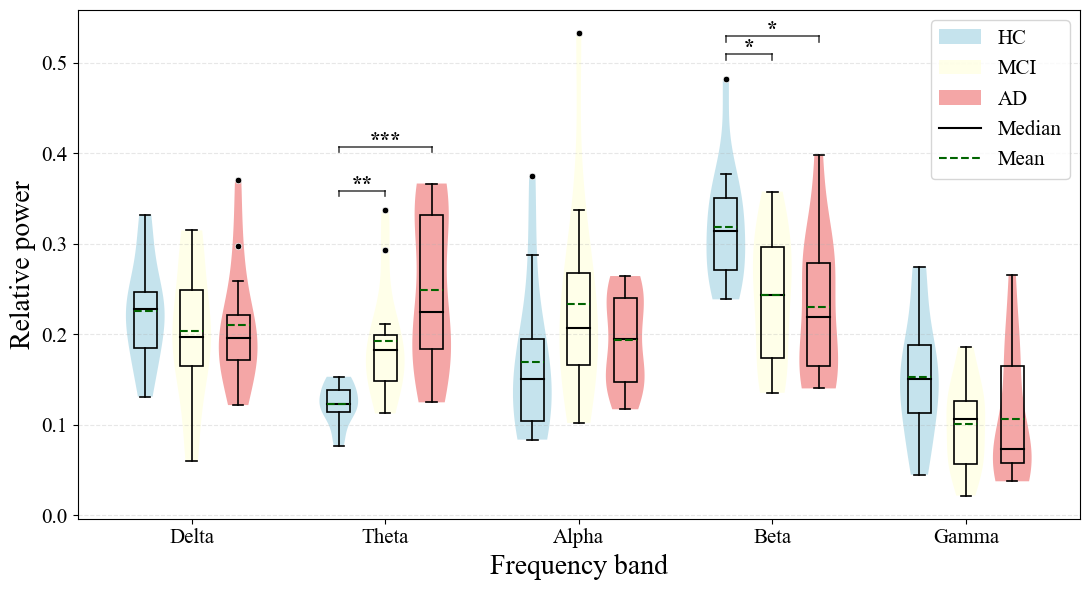

WindowsPath('C:/Python_Code/ADMamba/figs/befor_Relative_DeltaThetaAlphaBetaGamma_NCMCIAD_violin.svg')

In [12]:
# 调用所有绘图函数
# 可以修改参数来绘制不同的范式、状态和评估期

# 设置参数
assess = 'Assess-01'
paradigm = 'resting state befor'
state = 'open eyes'

print("\n绘制五频段 Whole Brain 合并小提琴图（相对功率，HC/MCI/AD）...")
plot_relative_band_power_whole_brain_violins_nc_mci_ad(
    paradigm=paradigm,
    state=state,
    assess=assess,
    x_tick_fontsize=15,     # 横坐标刻度数字
    y_tick_fontsize=15,     # 纵坐标刻度数字
    xlabel_fontsize=20,     # 横坐标轴标题
    ylabel_fontsize=20,     # 纵坐标轴标题
    legend_fontsize=15,     # 图例
    sig_fontsize=15,        # 显著性标签
)


## 计算不同不同频带功率在人群之间的Effect Size（效应量）

In [13]:
# 计算不同不同频带功率在人群之间的Effect Size（效应量）
from sklearn.utils import resample

def cohens_d(x1, x2):
    """
    Calculate Cohen's d effect size.
    Parameters
    ----------
    x1 : array-like
        Group 1 data
    x2 : array-like
        Group 2 data
    Returns
    -------
    d : float
        Cohen's d
    """
    x1 = np.asarray(x1)
    x2 = np.asarray(x2)
    n1 = len(x1)
    n2 = len(x2)
    mean1 = np.mean(x1)
    mean2 = np.mean(x2)
    std1 = np.std(x1, ddof=1)
    std2 = np.std(x2, ddof=1)
    # pooled standard deviation
    pooled_std = np.sqrt(
        ((n1 - 1) * std1**2 + (n2 - 1) * std2**2)
        / (n1 + n2 - 2)
    )
    d = (mean1 - mean2) / pooled_std
    return d

def hedges_g(x1, x2):
    """
    Calculate Hedges' g effect size.
    Parameters
    ----------
    x1 : array-like
        Group 1 data
    x2 : array-like
        Group 2 data
    Returns
    -------
    g : float
        Hedges' g
    """
    x1 = np.asarray(x1)
    x2 = np.asarray(x2)
    n1 = len(x1)
    n2 = len(x2)
    mean1 = np.mean(x1)
    mean2 = np.mean(x2)
    std1 = np.std(x1, ddof=1)
    std2 = np.std(x2, ddof=1)
    pooled_std = np.sqrt(
        ((n1 - 1) * std1**2 + (n2 - 1) * std2**2)
        / (n1 + n2 - 2)
    )
    d = (mean1 - mean2) / pooled_std
    # correction factor
    correction = 1 - (3 / (4 * (n1 + n2) - 9))
    g = correction * d
    return g

def bootstrap_hedges_g(x1, x2, n_boot=5000):
    values = []
    for _ in range(n_boot):
        b1 = resample(x1)
        b2 = resample(x2)
        values.append(hedges_g(b1, b2))
    lower = np.percentile(values, 2.5)
    upper = np.percentile(values, 97.5)
    return np.mean(values), (lower, upper)

In [14]:
# 相对频段功率：HC / MCI / AD 组间效应量（与上方小提琴图数据来源一致）
try:
    from IPython.display import display
except ImportError:
    display = print


def _metric_mean(metric_stats):
    """从指标统计结构中取均值（兼容扁平或单层嵌套结构）。"""
    if not metric_stats:
        return None
    if 'mean' in metric_stats:
        return metric_stats['mean']
    for v in metric_stats.values():
        if isinstance(v, dict) and 'mean' in v:
            return v['mean']
    return None


def collect_band_means_by_group(metrics, paradigm, state, assess):
    """每位受试者取各 metric 的 mean，按 HC/MCI/AD 分组（与小提琴图函数数据来源一致）。"""
    categories = ['HC', 'MCI', 'AD']
    if 'assess01_statistics' not in globals():
        raise RuntimeError('assess01_statistics 未定义，请先运行统计汇总相关单元')
    stats_data = assess01_statistics
    if paradigm not in stats_data or state not in stats_data[paradigm]:
        raise KeyError(f'无数据: {paradigm} / {state}')

    out = {m: {c: [] for c in categories} for m in metrics}
    for subject_name in stats_data[paradigm][state].keys():
        category = get_subject_category(subject_name, assess, 'ternary')
        if not category:
            continue
        subject_stats = stats_data[paradigm][state][subject_name]
        for metric in metrics:
            mean_val = _metric_mean(subject_stats.get(metric))
            if mean_val is None:
                continue
            out[metric][category].append(mean_val)
    return out


def fdr_bh_adjust(p_values):
    """Benjamini-Hochberg FDR 调整 P 值；NaN 保留为 NaN。"""
    p = np.asarray(p_values, dtype=float)
    out = np.full(p.shape, np.nan, dtype=float)
    mask = np.isfinite(p)
    n = int(mask.sum())
    if n == 0:
        return out
    pv = p[mask]
    order = np.argsort(pv)
    ranked = pv[order]
    adj = ranked * n / np.arange(1, n + 1)
    adj = np.minimum.accumulate(np.clip(adj[::-1], 0, 1))[::-1]
    restored = np.empty(n, dtype=float)
    restored[order] = adj
    out[mask] = restored
    return out


def band_power_effect_size_table(plot_data, metrics, group_pairs=None, alpha=0.05):
    """组对比较：Hedges' g、Mann-Whitney U 双侧 P 值，并对表内全部有效检验做 FDR-BH 校正。"""
    if group_pairs is None:
        group_pairs = [('HC', 'MCI'), ('HC', 'AD'), ('MCI', 'AD')]
    rows = []
    for metric in metrics:
        for g1, g2 in group_pairs:
            x1 = np.asarray(plot_data[metric][g1], dtype=float)
            x2 = np.asarray(plot_data[metric][g2], dtype=float)
            n1, n2 = len(x1), len(x2)
            row = {
                'metric': metric,
                'group1': g1,
                'group2': g2,
                'n1': n1,
                'n2': n2,
                'hedges_g': np.nan,
                'p_value': np.nan,
            }
            if n1 >= 2 and n2 >= 2:
                try:
                    row['hedges_g'] = hedges_g(x1, x2)
                except (FloatingPointError, ZeroDivisionError, ValueError):
                    pass
                try:
                    _, row['p_value'] = stats.mannwhitneyu(x1, x2, alternative='two-sided')
                except (FloatingPointError, ZeroDivisionError, ValueError):
                    pass
            rows.append(row)
    df = pd.DataFrame(rows)
    df['p_fdr_bh'] = fdr_bh_adjust(df['p_value'])
    df['significant_fdr_bh'] = df['p_fdr_bh'] < alpha
    df.loc[df['p_fdr_bh'].isna(), 'significant_fdr_bh'] = False
    df['hedges_g'] = df['hedges_g'].round(2)
    keep_cols = [
        'metric', 'group1', 'group2', 'n1', 'n2',
        'hedges_g', 'p_value', 'p_fdr_bh', 'significant_fdr_bh',
    ]
    return df[keep_cols]

In [15]:
assess = 'Assess-01'
state = 'open eyes'
paradigm = 'resting state befor'
relative_band_metrics = list(metrics_to_calculate)

print('=' * 80)
print(f'相对频段功率效应量 | {assess} | {paradigm} | {state}')
print('说明：Cohen d / Hedges g 为 (group1 − group2) 方向；正值表示 group1 均值更高')
print('=' * 80)

es_out_name = 'befor_effect_size_relative_band_power.xlsx'
es_out_path = save_path / es_out_name

print(f'\n计算: {paradigm} ...')
rel_by_group = collect_band_means_by_group(
    relative_band_metrics, paradigm, state, assess,
)
df_es = band_power_effect_size_table(
    rel_by_group, relative_band_metrics,
)
n_tests = int(df_es['p_value'].notna().sum())
print(f'FDR-BH: 对表内 {n_tests} 项有效检验做多重校正 (α = 0.05)')
with pd.ExcelWriter(es_out_path, engine='openpyxl') as writer:
    df_es.to_excel(writer, sheet_name='befor', index=False)
print(f'已写入 sheet「befor」({len(df_es)} 行)')
print(f'Excel 已写入: {es_out_path}')

相对频段功率效应量 | Assess-01 | resting state befor | open eyes
说明：Cohen d / Hedges g 为 (group1 − group2) 方向；正值表示 group1 均值更高

计算: resting state befor ...
FDR-BH: 对表内 15 项有效检验做多重校正 (α = 0.05)
已写入 sheet「befor」(15 行)
Excel 已写入: C:\Python_Code\ADMamba\figs\befor_effect_size_relative_band_power.xlsx


## 绘制具有效应值的小提琴图

In [16]:
def plot_relative_band_power_whole_brain_violins_nc_mci_ad(
    paradigm='resting state befor',
    state='open eyes',
    assess='Assess-01',
    fig_width=11,
    fig_height=6,
    x_tick_fontsize=12,
    y_tick_fontsize=12,
    xlabel_fontsize=12,
    ylabel_fontsize=12,
    legend_fontsize=10,
    sig_fontsize=10,
    es_fontsize=10,
    es_y_offset=0.0,
    es_bracket_gap=None,
    ylim=None,
    show_preview=True,
):
    """Whole Brain: five relative bands on x-axis, HC/MCI/AD violins per band.

    字体大小参数:
    - x_tick_fontsize / y_tick_fontsize: 横/纵坐标刻度数字
    - xlabel_fontsize / ylabel_fontsize: 横/纵坐标轴标题
    - legend_fontsize: 图例
    - sig_fontsize: 上方显著性括号标注
    - es_fontsize: 小提琴下方组间 Hedges' g 标注
    - es_y_offset: 只移动效应量数字，不移动组间括号。正值上移，负值下移（与纵轴同一坐标）
    - es_bracket_gap: 相邻两组括号的上下间隔，与纵轴同一坐标。None 时自动，数值越大间隔越大
    - ylim: 纵坐标上下限 (ymin, ymax)；None 时按数据自动设定
    - fig_width / fig_height: 图片宽度与高度（英寸）
    - show_preview: 是否在终端/Notebook 输出中显示图片

    效应量：Hedges' g = (左侧组均值 − 右侧组均值) / 合并标准差，
    组顺序为 HC、MCI、AD。数值保留四位小数，画在对应两组小提琴下方，
    括号连接方式与上方显著性标注相同。
    """
    if 'assess01_statistics' not in globals():
        print('Error: assess01_statistics not found')
        return
    stats_data = assess01_statistics

    metrics = list(metrics_to_calculate)
    band_labels = _BAND_LABELS[: len(metrics)]

    if paradigm not in stats_data or state not in stats_data[paradigm]:
        print(f'No data for {paradigm} / {state}')
        return

    plt.rcParams['font.family'] = 'Times New Roman'
    plt.rcParams['axes.unicode_minus'] = False

    categories = ['HC', 'MCI', 'AD']
    colors_map = {'HC': 'lightblue', 'MCI': 'lightyellow', 'AD': 'lightcoral'}
    region = 'Whole Brain'

    plot_data = {m: {cat: [] for cat in categories} for m in metrics}
    for subject_name in stats_data[paradigm][state].keys():
        category = get_subject_category(subject_name, assess, 'ternary')
        if not category:
            continue
        subject_stats = stats_data[paradigm][state][subject_name]
        for metric in metrics:
            st = subject_stats.get(metric)
            if not st or region not in st:
                continue
            plot_data[metric][category].append(st[region]['mean'])

    paradigm_suffix = paradigm.split()[-1] if paradigm.strip() else 'unknown'
    out_name = f'{paradigm_suffix}_Relative_DeltaThetaAlphaBetaGamma_NCMCIAD_violin.svg'

    n_bands = len(metrics)
    band_centers = np.arange(1, n_bands + 1, dtype=float)
    spread = 0.24
    offsets = np.linspace(-spread, spread, len(categories))

    def x_for(band_idx, cat):
        return band_centers[band_idx] + offsets[categories.index(cat)]

    all_positions, all_data, all_colors = [], [], []
    pos_by_band_cat = {}
    for band_idx, metric in enumerate(metrics):
        for cat in categories:
            arr = np.array(plot_data[metric][cat])
            if len(arr) == 0:
                continue
            pos = float(x_for(band_idx, cat))
            pos_by_band_cat[(band_idx, cat)] = pos
            all_positions.append(pos)
            all_data.append(arr)
            all_colors.append(colors_map[cat])

    fig, ax = plt.subplots(figsize=(fig_width, fig_height))

    if not all_data:
        ax.set_xticks(band_centers)
        ax.set_xticklabels(band_labels, fontsize=x_tick_fontsize, fontfamily='Times New Roman')
        ax.text(0.5, 0.5, 'No data', ha='center', va='center', transform=ax.transAxes,
                fontsize=x_tick_fontsize, fontfamily='Times New Roman')
    else:
        v_width = min(0.2, spread * 0.85)
        parts = ax.violinplot(
            all_data, positions=all_positions, widths=v_width,
            showmeans=False, showmedians=False, showextrema=False,
        )
        for pc, color in zip(parts['bodies'], all_colors):
            pc.set_facecolor(color)
            pc.set_alpha(0.7)

        box_width = min(0.12, v_width * 0.65)
        for pos, data in zip(all_positions, all_data):
            q1, median, q3 = np.percentile(data, [25, 50, 75])
            iqr = q3 - q1
            lower_whisker = max(q1 - 1.5 * iqr, np.min(data))
            upper_whisker = min(q3 + 1.5 * iqr, np.max(data))
            lower_pos = np.min(data[data >= lower_whisker])
            upper_pos = np.max(data[data <= upper_whisker])
            mean_val = np.mean(data)
            rect = plt.Rectangle(
                (pos - box_width / 2, q1), box_width, q3 - q1,
                fill=False, edgecolor='black', linewidth=1.2, zorder=10,
            )
            ax.add_patch(rect)
            ax.plot([pos - box_width / 2, pos + box_width / 2], [median, median], 'k-', linewidth=1.5, zorder=11)
            ax.plot(
                [pos - box_width / 2, pos + box_width / 2],
                [mean_val, mean_val],
                linestyle='--', color='darkgreen', linewidth=1.5, zorder=12,
            )
            ax.plot([pos, pos], [q1, lower_pos], 'k-', linewidth=1.2, zorder=10)
            ax.plot([pos, pos], [q3, upper_pos], 'k-', linewidth=1.2, zorder=10)
            whisker_w = box_width * 0.45
            ax.plot([pos - whisker_w / 2, pos + whisker_w / 2], [lower_pos, lower_pos], 'k-', linewidth=1.2, zorder=10)
            ax.plot([pos - whisker_w / 2, pos + whisker_w / 2], [upper_pos, upper_pos], 'k-', linewidth=1.2, zorder=10)
            outliers = data[(data < lower_whisker) | (data > upper_whisker)]
            if len(outliers) > 0:
                ax.scatter(
                    [pos] * len(outliers), outliers, s=22, color='black', marker='o',
                    edgecolors='white', linewidths=0.5, zorder=12,
                )

        def _hedges_g(x1, x2):
            """Hedges' g: (mean of earlier group − mean of later group) / pooled SD."""
            x1 = np.asarray(x1, dtype=float)
            x2 = np.asarray(x2, dtype=float)
            n1, n2 = len(x1), len(x2)
            if n1 < 2 or n2 < 2:
                return np.nan
            s1 = np.std(x1, ddof=1)
            s2 = np.std(x2, ddof=1)
            pooled = np.sqrt(((n1 - 1) * s1 ** 2 + (n2 - 1) * s2 ** 2) / (n1 + n2 - 2))
            if not np.isfinite(pooled) or pooled == 0:
                return np.nan
            d = (np.mean(x1) - np.mean(x2)) / pooled
            correction = 1 - (3 / (4 * (n1 + n2) - 9))
            return correction * d

        global_lo = min(float(np.min(a)) for a in all_data)
        global_hi = max(float(np.max(a)) for a in all_data)
        global_span = global_hi - global_lo if global_hi > global_lo else 1.0
        es_base = global_span * 0.055
        es_tick = global_span * 0.015
        bracket_gap = es_base if es_bracket_gap is None else float(es_bracket_gap)

        for band_idx, metric in enumerate(metrics):
            region_categories = [cat for cat in categories if len(plot_data[metric][cat]) > 0]
            region_data_dict = {cat: np.array(plot_data[metric][cat]) for cat in region_categories}
            bracket_idx = 0
            for i, cat1 in enumerate(region_categories):
                for cat2 in region_categories[i + 1:]:
                    data1 = region_data_dict[cat1]
                    data2 = region_data_dict[cat2]
                    if len(data1) == 0 or len(data2) == 0:
                        continue
                    cat1_pos = pos_by_band_cat.get((band_idx, cat1))
                    cat2_pos = pos_by_band_cat.get((band_idx, cat2))
                    if cat1_pos is None or cat2_pos is None:
                        continue
                    try:
                        _, p_value = stats.mannwhitneyu(data1, data2, alternative='two-sided')
                        sig_label = '***' if p_value < 0.001 else '**' if p_value < 0.01 else '*' if p_value < 0.05 else 'ns'
                        if sig_label == 'ns':
                            continue
                        y_hi = max(np.max(data1), np.max(data2))
                        y_lo = min(np.min(data1), np.min(data2))
                        y_range = y_hi - y_lo if y_hi > y_lo else (abs(y_hi) * 0.1 if y_hi != 0 else 1.0)
                        line_top = y_hi + y_range * (0.08 + bracket_idx * 0.06)
                        line_bottom = line_top - y_range * 0.02
                        text_y = line_top - 0.005
                        ax.plot([cat1_pos, cat2_pos], [line_top, line_top], 'k-', linewidth=1.2, alpha=0.7)
                        ax.plot([cat1_pos, cat1_pos], [line_bottom, line_top], 'k-', linewidth=1.2, alpha=0.7)
                        ax.plot([cat2_pos, cat2_pos], [line_bottom, line_top], 'k-', linewidth=1.2, alpha=0.7)
                        ax.text(
                            (cat1_pos + cat2_pos) / 2, text_y, sig_label,
                            ha='center', va='bottom', fontsize=sig_fontsize, fontweight='bold',
                            fontfamily='Times New Roman',
                        )
                        bracket_idx += 1
                    except Exception:
                        pass

            # Hedges' g below the violins; brackets identify the same group pairs as significance
            if len(region_categories) >= 2:
                y_lo_band = min(np.min(region_data_dict[c]) for c in region_categories)
                es_idx = 0
                for i, cat1 in enumerate(region_categories):
                    for cat2 in region_categories[i + 1:]:
                        data1 = region_data_dict[cat1]
                        data2 = region_data_dict[cat2]
                        if len(data1) < 2 or len(data2) < 2:
                            continue
                        cat1_pos = pos_by_band_cat.get((band_idx, cat1))
                        cat2_pos = pos_by_band_cat.get((band_idx, cat2))
                        if cat1_pos is None or cat2_pos is None:
                            continue
                        g_val = _hedges_g(data1, data2)
                        if not np.isfinite(g_val):
                            continue
                        line_bot = y_lo_band - es_base - es_idx * bracket_gap
                        tick_top = line_bot + es_tick
                        ax.plot([cat1_pos, cat2_pos], [line_bot, line_bot], 'k-', linewidth=1.2, alpha=0.7, clip_on=False)
                        ax.plot([cat1_pos, cat1_pos], [line_bot, tick_top], 'k-', linewidth=1.2, alpha=0.7, clip_on=False)
                        ax.plot([cat2_pos, cat2_pos], [line_bot, tick_top], 'k-', linewidth=1.2, alpha=0.7, clip_on=False)
                        ax.text(
                            (cat1_pos + cat2_pos) / 2, line_bot + es_y_offset, f'{g_val:.4f}',
                            ha='center', va='top', fontsize=es_fontsize,
                            fontfamily='Times New Roman', clip_on=False,
                        )
                        es_idx += 1

    ax.set_xticks(band_centers)
    ax.set_xticklabels(band_labels, fontsize=x_tick_fontsize, fontfamily='Times New Roman')
    ax.set_xlabel('Frequency band', fontsize=xlabel_fontsize, fontfamily='Times New Roman')
    ax.set_ylabel('Relative power', fontsize=ylabel_fontsize, fontfamily='Times New Roman')
    ax.tick_params(axis='y', labelsize=y_tick_fontsize)
    ax.set_xlim(band_centers[0] - spread - 0.35, band_centers[-1] + spread + 0.35)
    if ylim is None:
        ax.relim()
        ax.autoscale_view()
        y0, y1 = ax.get_ylim()
        y_pad = (y1 - y0) * 0.10 if y1 > y0 else 0.05
        ax.set_ylim(y0 - y_pad, y1)
    else:
        ax.set_ylim(ylim)
    ax.grid(True, alpha=0.3, linestyle='--', axis='y')

    legend_handles = [Patch(facecolor=colors_map[cat], alpha=0.7, label=cat) for cat in categories]
    legend_handles += [
        Line2D([0], [0], color='black', linewidth=1.5, linestyle='-', label='Median'),
        Line2D([0], [0], color='darkgreen', linewidth=1.5, linestyle='--', label='Mean'),
    ]
    ax.legend(
        handles=legend_handles, loc='best',
        prop={'family': 'Times New Roman', 'size': legend_fontsize},
    )
    plt.tight_layout()
    out_path = save_path / out_name
    fig.savefig(out_path, format='svg', bbox_inches='tight', facecolor='white')
    print(f'[relative band power] Whole Brain HC/MCI/AD violin: {out_path}')

    if show_preview:
        try:
            from IPython.display import display
            display(fig)
        except ImportError:
            plt.show()

    plt.close(fig)
    return out_path


绘制五频段 Whole Brain 合并小提琴图（相对功率，HC/MCI/AD，含效应量）...
[relative band power] Whole Brain HC/MCI/AD violin: C:\Python_Code\ADMamba\figs\befor_Relative_DeltaThetaAlphaBetaGamma_NCMCIAD_violin.svg


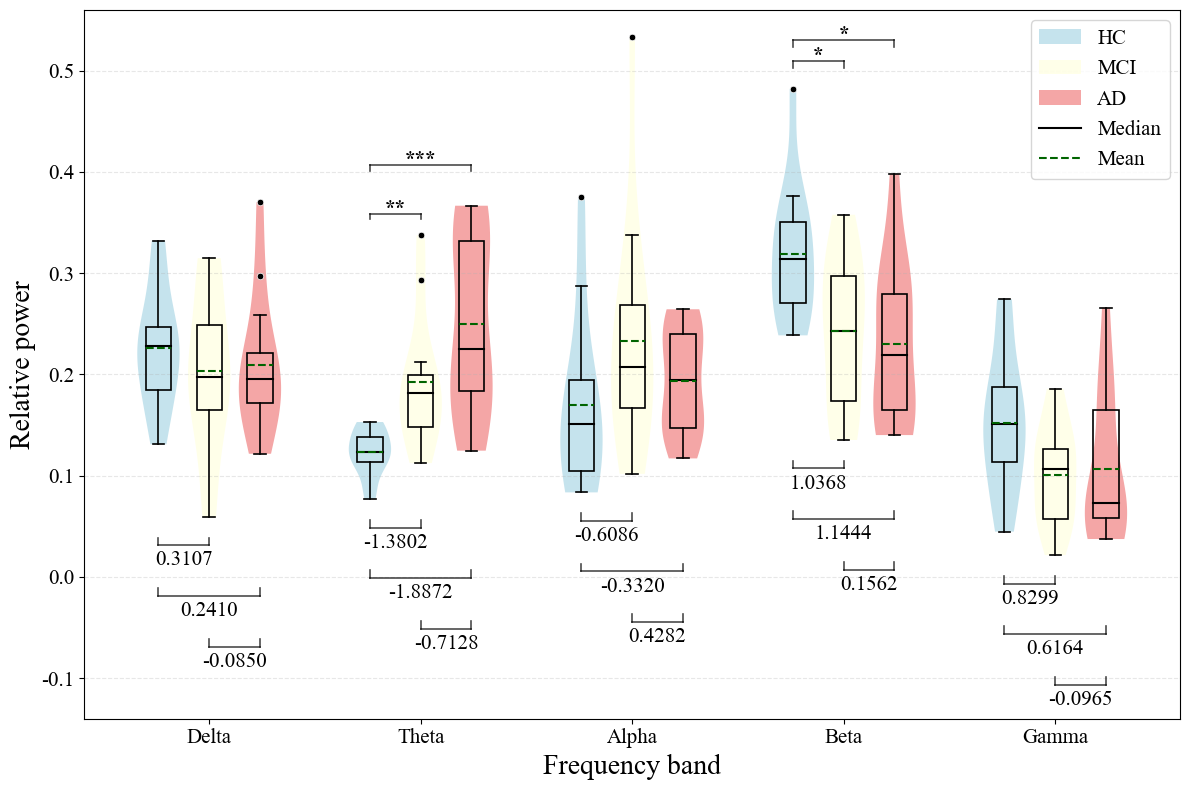

WindowsPath('C:/Python_Code/ADMamba/figs/befor_Relative_DeltaThetaAlphaBetaGamma_NCMCIAD_violin.svg')

In [17]:
# 绘制五频段 Whole Brain 小提琴图，并在小提琴下方标注组间 Hedges' g（四位小数）
assess = 'Assess-01'
paradigm = 'resting state befor'
state = 'open eyes'

print('\n绘制五频段 Whole Brain 合并小提琴图（相对功率，HC/MCI/AD，含效应量）...')
plot_relative_band_power_whole_brain_violins_nc_mci_ad(
    paradigm=paradigm,
    state=state,
    assess=assess,
    fig_width=12,
    fig_height=8,
    x_tick_fontsize=15,     # 横坐标刻度数字
    y_tick_fontsize=15,     # 纵坐标刻度数字
    xlabel_fontsize=20,     # 横坐标轴标题
    ylabel_fontsize=20,     # 纵坐标轴标题
    legend_fontsize=15,     # 图例
    sig_fontsize=15,        # 显著性标签
    es_fontsize=15,         # 小提琴下方效应量
    es_y_offset=-0.005,          # 只移动效应量数字，正值上移、负值下移
    es_bracket_gap=0.05,        # 相邻两组括号的上下间隔，None 为自动
    ylim=(-0.14, 0.56),              # 纵坐标上下限 (ymin, ymax)，None 为自动
)
